<a href="https://colab.research.google.com/github/mohameniyaz/l20niyazcat2/blob/main/Niyazdl.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. Kaggle Authentication and Dataset Download
Before running the cell below, ensure you have uploaded your `kaggle.json` file to your Colab session or saved it in your Google Drive/Colab secrets.

In [ ]:
import os
import pandas as pd

# Configure Kaggle API credentials directory
os.makedirs('/root/.kaggle', exist_ok=True)

# If you have kaggle.json in your current directory, we copy it to the correct path
if os.path.exists('kaggle.json'):
    !cp kaggle.json ~/.kaggle/
    !chmod 600 ~/.kaggle/kaggle.json
    print("Kaggle API key configured from uploaded file.")
else:
    print("Please upload your 'kaggle.json' file to the environment or set up your Kaggle credentials to download the dataset automatically.")

Please upload your 'kaggle.json' file to the environment or set up your Kaggle credentials to download the dataset automatically.


### 2. Downloading Bitcoin Historical Data
We will download the popular 'Coinbase USD (BTCUSD) daily historical dataset' or a general cryptocurrency dataset from Kaggle.

In [ ]:
# Download cryptocurrency historical dataset directly using yfinance to bypass Kaggle auth issues
!pip install -q yfinance

import yfinance as yf
import pandas as pd

# Fetch Bitcoin historical data (BTC-USD)
# Let's request a wide range to easily extract 2,000 consecutive records
ticker = 'BTC-USD'
btc_data = yf.download(ticker, start='2016-01-01', end='2024-01-01')

# Save to csv to maintain the file-loading pipeline structure if desired
btc_data.to_csv('/tmp/bitcoin_historical_data.csv')

/tmp/ipykernel_6373/1160840544.py:10: FutureWarning: YF.download() has changed argument auto_adjust default to True
  btc_data = yf.download(ticker, start='2016-01-01', end='2024-01-01')
[*********************100%***********************]  1 of 1 completed


### 3. Loading and Selecting 2,000 Consecutive Daily Records
We will read the dataset, parse the timestamps to daily granularity, and select a subset of 2,000 consecutive days of Bitcoin data.

In [ ]:
import os
import pandas as pd

csv_path = '/tmp/bitcoin_historical_data.csv'

if os.path.exists(csv_path):
    # Load the CSV, bypassing both metadata headers cleanly
    df_daily = pd.read_csv(csv_path, header=0, skiprows=[1])

    # Explicitly rename the first column to 'Date'
    df_daily.rename(columns={df_daily.columns[0]: 'Date'}, inplace=True)

    # Remove any extra header metadata row (where 'Date' is string value 'Date')
    df_daily = df_daily[df_daily['Date'] != 'Date']

    # Ensure Date column is in datetime format
    df_daily['Date'] = pd.to_datetime(df_daily['Date'], errors='coerce')

    # Drop rows without a valid date
    df_daily = df_daily.dropna(subset=['Date'])

    # Sort by chronological order
    df_daily = df_daily.sort_values('Date').reset_index(drop=True)

    # Convert numeric columns to float explicitly
    for price_col in ['Open', 'High', 'Low', 'Close', 'Volume']:
        if price_col in df_daily.columns:
            df_daily[price_col] = pd.to_numeric(df_daily[price_col], errors='coerce')

    # Drop any potential NaN values in the target column
    df_daily = df_daily.dropna(subset=['Close'])

    # Select a manageable subset of exactly 2,000 consecutive records
    df_subset = df_daily.head(2000).reset_index(drop=True)

    print(f"Successfully loaded and prepared dataset!")
    print(f"Subset shape: {df_subset.shape} (from {df_subset['Date'].min().strftime('%Y-%m-%d')} to {df_subset['Date'].max().strftime('%Y-%m-%d')})")
    display(df_subset.head())
else:
    print("Historical data file not found. Please run the download cell above.")

Successfully loaded and prepared dataset!
Subset shape: (2000, 6) (from 2016-01-01 to 2021-06-22)


,Date,Close,High,Low,Open,Volume
0,2016-01-01,434.334015,436.246002,427.515015,430.721008,36278900.0
1,2016-01-02,433.437988,436.062012,431.869995,434.622009,30096600.0
2,2016-01-03,430.010986,433.743011,424.705994,433.578003,39633800.0
3,2016-01-04,433.091003,434.516998,429.084015,430.061005,38477500.0
4,2016-01-05,431.959991,434.182007,429.675995,433.069000,34522600.0


### 4. Visualize the Bitcoin Closing Price Trend
Let's plot the historical closing prices over the selected 2,000-day consecutive timeline to understand the general trend and price patterns.

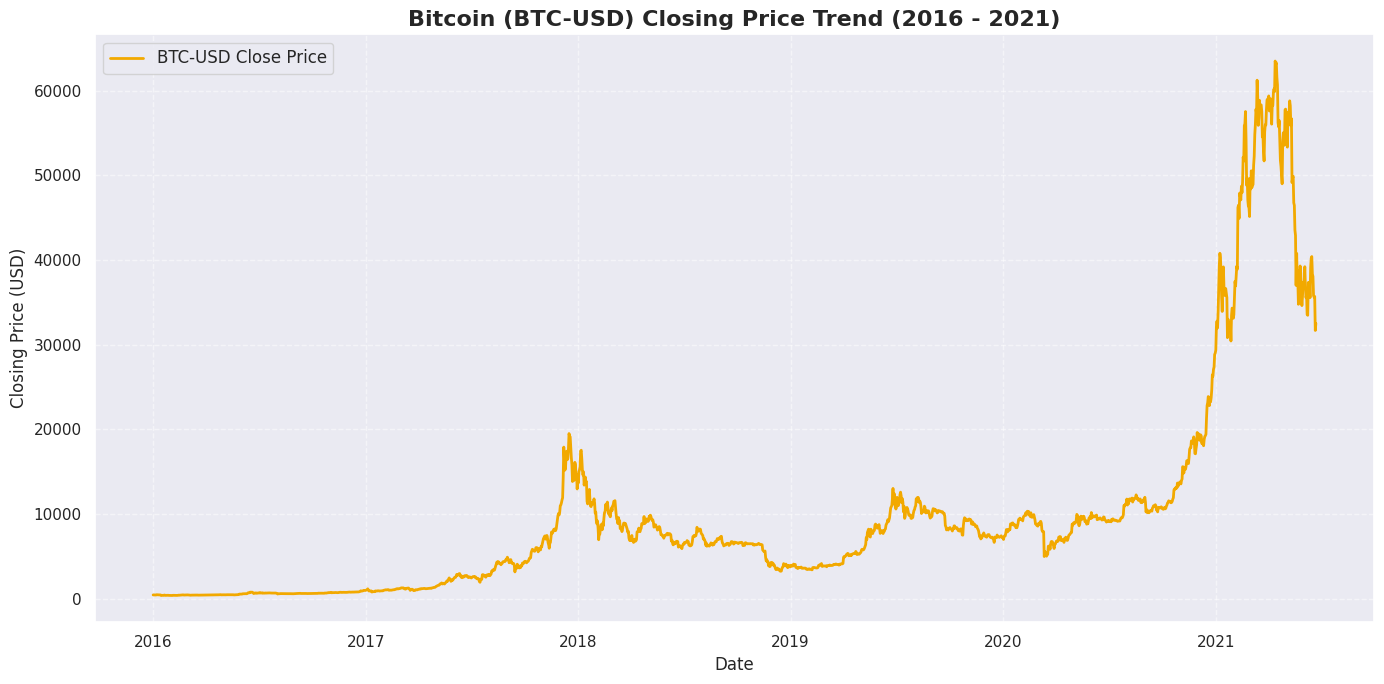

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configure plot styling
sns.set_theme(style="darkgrid")
plt.figure(figsize=(14, 7))

# Plot the historical closing price
plt.plot(df_subset['Date'], df_subset['Close'], label='BTC-USD Close Price', color='#f2a900', linewidth=2)

# Set labels and title
plt.title('Bitcoin (BTC-USD) Closing Price Trend (2016 - 2021)', fontsize=16, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Closing Price (USD)', fontsize=12)
plt.legend(loc='upper left', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)

# Display plot
plt.tight_layout()
plt.show()

### 5. Feature Engineering: Creating Lag Features
To predict the next day's closing price ($t+1$), we will construct features using historical closing prices from previous days:
* **Target**: `Target_Close` (Close price of the next day, $t+1$)
* **Features**: `Close_Lag_1` ($t$), `Close_Lag_2` ($t-1$), `Close_Lag_3` ($t-2$), and `Close_Lag_7` ($t-6$)

Creating these lag variables allows standard machine learning algorithms to model the temporal dependencies in sequential data.

In [ ]:
# Create copy of the subset to work on features safely
df_features = df_subset[['Date', 'Close', 'Open', 'High', 'Low', 'Volume']].copy()

# Create the target variable: Next day's closing price (t+1)
df_features['Target_Close'] = df_features['Close'].shift(-1)

# Create historical lag features relative to day t (current Close is lag 1)
df_features['Close_Lag_1'] = df_features['Close']
df_features['Close_Lag_2'] = df_features['Close'].shift(1)

# Additional lags for capturing weekly trends
df_features['Close_Lag_3'] = df_features['Close'].shift(2)
df_features['Close_Lag_7'] = df_features['Close'].shift(6)

# Drop NaN values resulting from shifting
df_features_clean = df_features.dropna().reset_index(drop=True)

print(f"Feature matrix shape after dropping NaNs: {df_features_clean.shape}")
display(df_features_clean[['Date', 'Close_Lag_7', 'Close_Lag_3', 'Close_Lag_2', 'Close_Lag_1', 'Target_Close']].head(10))

Feature matrix shape after dropping NaNs: (1993, 11)


,Date,Close_Lag_7,Close_Lag_3,Close_Lag_2,Close_Lag_1,Target_Close
0,2016-01-07,434.334015,431.959991,429.105011,458.048004,453.230011
1,2016-01-08,433.437988,429.105011,458.048004,453.230011,447.610992
2,2016-01-09,430.010986,458.048004,453.230011,447.610992,447.990997
3,2016-01-10,433.091003,453.230011,447.610992,447.990997,448.428009
4,2016-01-11,431.959991,447.610992,447.990997,448.428009,435.690002
5,2016-01-12,429.105011,447.990997,448.428009,435.690002,432.371002
6,2016-01-13,458.048004,448.428009,435.690002,432.371002,430.306000
7,2016-01-14,453.230011,435.690002,432.371002,430.306000,364.330994
8,2016-01-15,447.610992,432.371002,430.306000,364.330994,387.536011
9,2016-01-16,447.990997,430.306000,364.330994,387.536011,382.299011


### 6. Feature Correlation Matrix
Let's calculate and plot the correlation matrix to see how strongly our historical lag features, current daily attributes, and target variable (`Target_Close`) are correlated with each other.

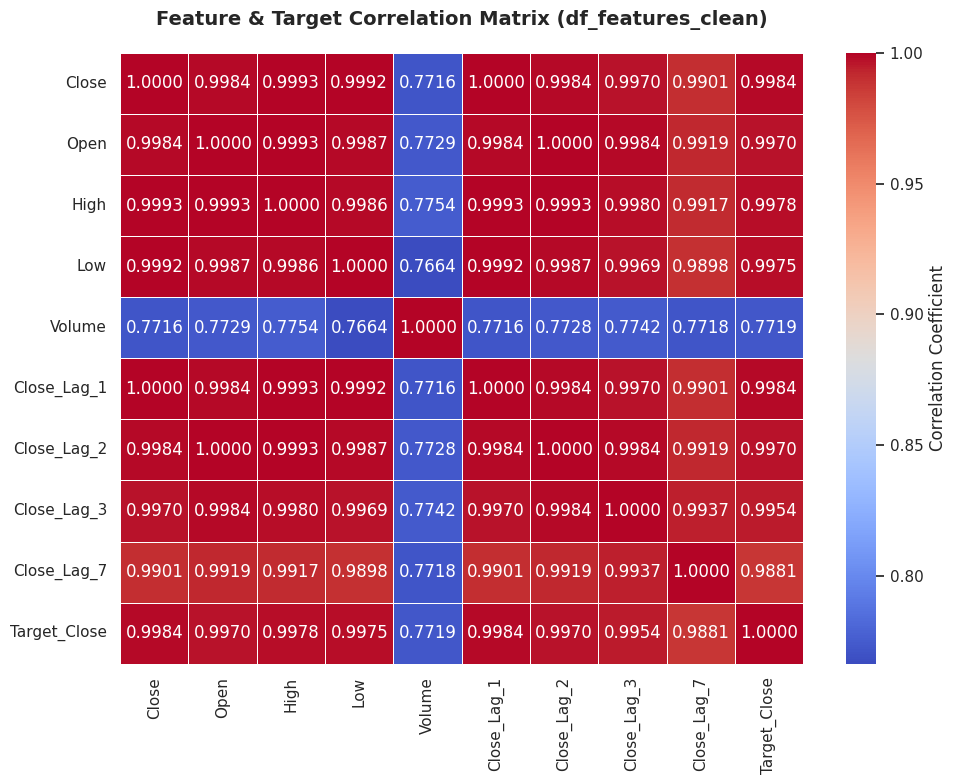

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical columns for correlation calculation
# Excluding 'Date' column
correlation_cols = [
    'Close', 'Open', 'High', 'Low', 'Volume',
    'Close_Lag_1', 'Close_Lag_2', 'Close_Lag_3', 'Close_Lag_7',
    'Target_Close'
]

# Compute correlation matrix
corr_matrix = df_features_clean[correlation_cols].corr()

# Set up matplotlib figure
plt.figure(figsize=(10, 8))

# Draw the heatmap with values and a custom color map
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".4f",
    cmap="coolwarm",
    linewidths=0.5,
    cbar_kws={"label": "Correlation Coefficient"}
)

# Set title and adjust layout
plt.title("Feature & Target Correlation Matrix (df_features_clean)", fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

### 7. Time-Series Train-Test Split
To avoid lookahead bias and evaluate our machine learning model realistically, we split the data sequentially. We will use the first 80% of the timeline for training and the remaining 20% for testing.

In [ ]:
# Define the feature columns and target variable
feature_cols = ['Close_Lag_1', 'Close_Lag_2', 'Close_Lag_3', 'Close_Lag_7']
target_col = 'Target_Close'

# Sort chronologically by date to be absolutely sure of sequential order
df_features_clean = df_features_clean.sort_values('Date').reset_index(drop=True)

# Determine the split index (80% train, 20% test)
split_idx = int(len(df_features_clean) * 0.8)

train_df = df_features_clean.iloc[:split_idx]
test_df = df_features_clean.iloc[split_idx:]

# Separate into features (X) and target (y)
X_train = train_df[feature_cols]
y_train = train_df[target_col]

X_test = test_df[feature_cols]
y_test = test_df[target_col]

# Display metadata about the split
print(f"Training set shape: {X_train.shape} (from {train_df['Date'].min().strftime('%Y-%m-%d')} to {train_df['Date'].max().strftime('%Y-%m-%d')})")
print(f"Testing set shape:  {X_test.shape} (from {test_df['Date'].min().strftime('%Y-%m-%d')} to {test_df['Date'].max().strftime('%Y-%m-%d')})")

Training set shape: (1594, 4) (from 2016-01-07 to 2020-05-18)
Testing set shape:  (399, 4) (from 2020-05-19 to 2021-06-21)


### 7.1. Systematic Feature Normalization and Preprocessing
For optimal training of neural network models (TensorFlow/Keras) and regularized models, we apply standardized scaling (`StandardScaler`) to our lag features. This normalizes our inputs to have a mean of 0 and a standard deviation of 1.

In [ ]:
from sklearn.preprocessing import StandardScaler

# Initialize scale operators for features
feature_scaler = StandardScaler()

# Fit on training data and transform both sets sequentially to avoid leakage
X_train_scaled = feature_scaler.fit_transform(X_train)
X_test_scaled = feature_scaler.transform(X_test)

# Let's inspect the normalized inputs
print("=== Normalized Feature Statistics (Train) ===")
print(f"Mean of scaled features: {X_train_scaled.mean(axis=0)}")
print(f"Std of scaled features:  {X_train_scaled.std(axis=0)}")

=== Normalized Feature Statistics (Train) ===
Mean of scaled features: [-7.13217301e-17  3.56608650e-17  3.56608650e-17  0.00000000e+00]
Std of scaled features:  [1. 1. 1. 1.]


### 8. Train and Evaluate Random Forest Regressor
We will now fit a Random Forest Regressor to our engineered features and evaluate its predictive accuracy on the unseen out-of-time test set.

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Initialize the Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions on training and testing sets
y_pred_train = rf_model.predict(X_train)
y_pred_test = rf_model.predict(X_test)

# Calculate evaluation metrics for the test set
mae = mean_absolute_error(y_test, y_pred_test)
mse = mean_squared_error(y_test, y_pred_test)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_test)

print("=== Model Evaluation Metrics ===")
print(f"Mean Absolute Error (MAE):     ${mae:,.2f}")
print(f"Root Mean Squared Error (RMSE): ${rmse:,.2f}")
print(f"R-squared (R2) Score:          {r2:.4f}")

=== Model Evaluation Metrics ===
Mean Absolute Error (MAE):     $12,647.87
Root Mean Squared Error (RMSE): $19,652.21
R-squared (R2) Score:          -0.1713


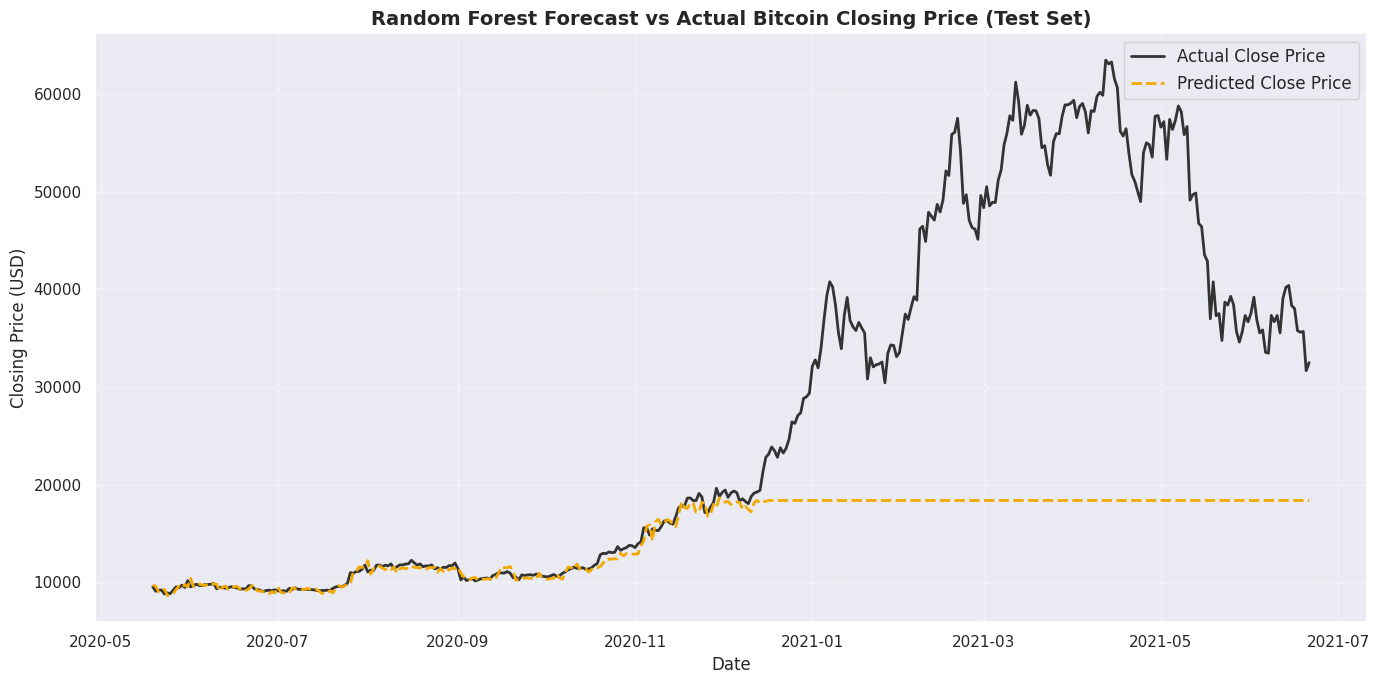

In [ ]:
# Plot predicted vs. actual prices for the test period
plt.figure(figsize=(14, 7))

test_dates = test_df['Date']

plt.plot(test_dates, y_test.values, label='Actual Close Price', color='#333333', linewidth=2)
plt.plot(test_dates, y_pred_test, label='Predicted Close Price', color='#f2a900', linestyle='--', linewidth=2)

plt.title('Random Forest Forecast vs Actual Bitcoin Closing Price (Test Set)', fontsize=14, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Closing Price (USD)', fontsize=12)
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### 9. Comparing with a Linear Regression Baseline
Unlike decision trees, a Linear Regression model fits a linear hyperplane over the feature space and can extrapolate predictions beyond the maximum training values.

In [ ]:
from sklearn.linear_model import LinearRegression

# Initialize and train the Linear Regression baseline
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Predict on the test set
y_pred_lr = lr_model.predict(X_test)

# Evaluation
mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr = r2_score(y_test, y_pred_lr)

print("=== Linear Regression Metrics ===")
print(f"Mean Absolute Error (MAE):     ${mae_lr:,.2f}")
print(f"Root Mean Squared Error (RMSE): ${rmse_lr:,.2f}")
print(f"R-squared (R2) Score:          {r2_lr:.4f}")

=== Linear Regression Metrics ===
Mean Absolute Error (MAE):     $854.49
Root Mean Squared Error (RMSE): $1,457.26
R-squared (R2) Score:          0.9936


### 10. Deep Learning Framework Implementation (TensorFlow & Keras)
Now, let's configure a deep learning model using **TensorFlow** and **Keras**. To ensure stable convergence, we will scale our features using `StandardScaler` from scikit-learn before feeding them into our neural network.

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from sklearn.preprocessing import StandardScaler

# Scale our features for deep learning stability
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Build a deep feedforward neural network
tf.random.set_seed(42)

model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(1) # Linear output for regression
])

# Compile the neural network with Adam optimizer and MSE loss
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.01), loss='mse')

# Train the neural network
history = model.fit(
    X_train_scaled, y_train,
    validation_split=0.1,
    epochs=100,
    batch_size=32,
    verbose=0
)

# Make predictions
y_pred_nn = model.predict(X_test_scaled).flatten()

# Evaluate the neural network predictions
mae_nn = mean_absolute_error(y_test, y_pred_nn)
rmse_nn = np.sqrt(mean_squared_error(y_test, y_pred_nn))
r2_nn = r2_score(y_test, y_pred_nn)

print("=== TensorFlow MLP Metrics ===")
print(f"Mean Absolute Error (MAE):     ${mae_nn:,.2f}")
print(f"Root Mean Squared Error (RMSE): ${rmse_nn:,.2f}")
print(f"R-squared (R2) Score:          {r2_nn:.4f}")

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
=== TensorFlow MLP Metrics ===
Mean Absolute Error (MAE):     $1,044.77
Root Mean Squared Error (RMSE): $1,675.11
R-squared (R2) Score:          0.9915


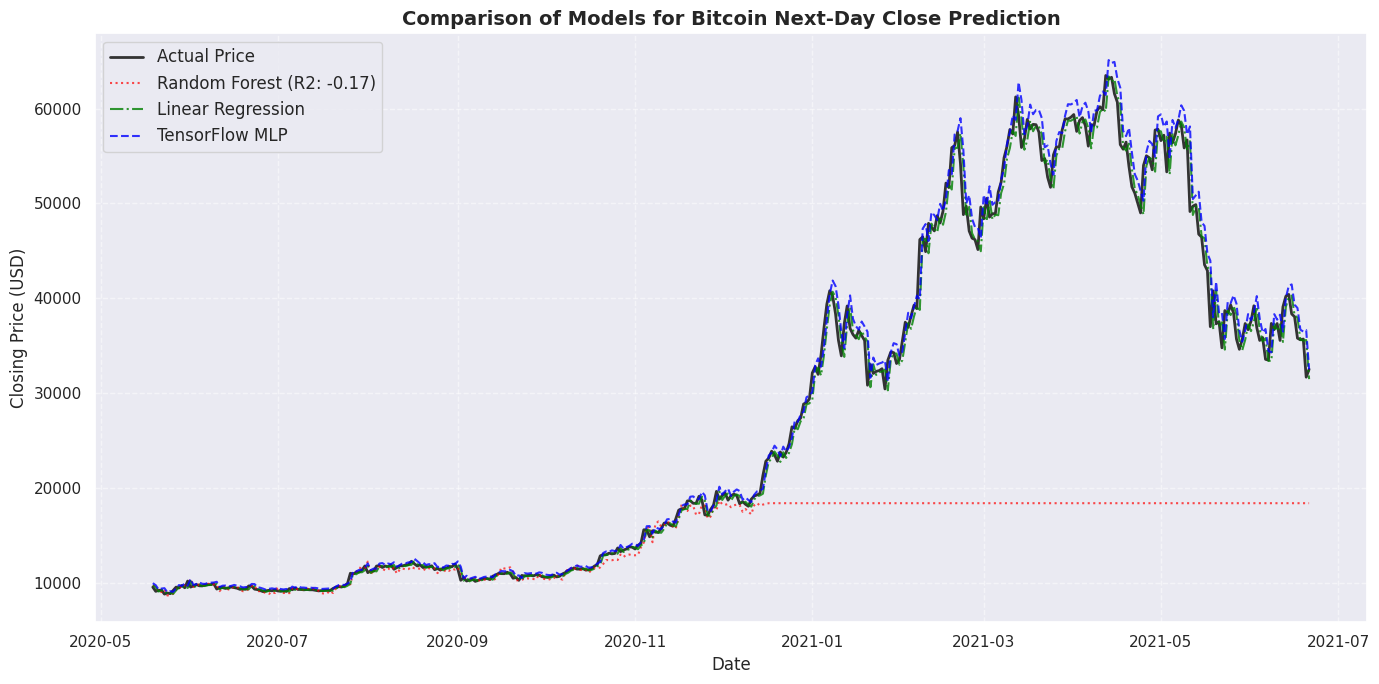

In [ ]:
# Compare the predictions visually
plt.figure(figsize=(14, 7))

plt.plot(test_dates, y_test.values, label='Actual Price', color='#333333', linewidth=2)
plt.plot(test_dates, y_pred_test, label='Random Forest (R2: -0.17)', color='red', linestyle=':', alpha=0.7)
plt.plot(test_dates, y_pred_lr, label='Linear Regression', color='green', linestyle='-.', alpha=0.8)
plt.plot(test_dates, y_pred_nn, label='TensorFlow MLP', color='blue', linestyle='--', alpha=0.8)

plt.title('Comparison of Models for Bitcoin Next-Day Close Prediction', fontsize=14, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Closing Price (USD)')
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### 11. Deep Learning Sequence Modeling: PyTorch LSTM
Let's construct a recurrent **LSTM (Long Short-Term Memory) network** using **PyTorch** to model temporal sequence dependencies. LSTMs are specifically designed to capture patterns in sequential time-series data.

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
from sklearn.preprocessing import StandardScaler

# Set random seed for PyTorch reproducibility
torch.manual_seed(42)

# Standardize targets as well to help LSTM learn mappings stably
target_scaler = StandardScaler()
y_train_scaled = target_scaler.fit_transform(y_train.values.reshape(-1, 1))
y_test_scaled = target_scaler.transform(y_test.values.reshape(-1, 1))

# Reshape scaled features to fit PyTorch LSTM expected input: (Batch Size, Sequence Length, Input Dimension)
X_train_lstm = X_train_scaled.reshape((X_train_scaled.shape[0], X_train_scaled.shape[1], 1))
X_test_lstm = X_test_scaled.reshape((X_test_scaled.shape[0], X_test_scaled.shape[1], 1))

# Convert arrays to PyTorch Tensors
X_train_tensor = torch.tensor(X_train_lstm, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_scaled, dtype=torch.float32)

X_test_tensor = torch.tensor(X_test_lstm, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test_scaled, dtype=torch.float32)

# Create PyTorch DataLoaders
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=False)

print(f"PyTorch LSTM Train Tensor Shape: {X_train_tensor.shape}")
print(f"PyTorch LSTM Test Tensor Shape:  {X_test_tensor.shape}")

PyTorch LSTM Train Tensor Shape: torch.Size([1594, 4, 1])
PyTorch LSTM Test Tensor Shape:  torch.Size([399, 4, 1])


In [ ]:
class BitcoinLSTM(nn.Module):
    def __init__(self, input_dim=1, hidden_dim=32, num_layers=1, output_dim=1):
        super(BitcoinLSTM, self).__init__()
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers

        # Single LSTM layer often performs better and generalizes smoother on short step windows
        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers, batch_first=True)

        # Fully connected layer
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim).to(x.device)
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim).to(x.device)

        out, _ = self.lstm(x, (h0, c0))
        out = self.fc(out[:, -1, :])
        return out

# Instantiate the model with a moderate learning rate for gradual convergence
model_lstm = BitcoinLSTM()
criterion = nn.MSELoss()
optimizer = optim.Adam(model_lstm.parameters(), lr=0.005)

print(model_lstm)

BitcoinLSTM(
  (lstm): LSTM(1, 32, batch_first=True)
  (fc): Linear(in_features=32, out_features=1, bias=True)
)


In [ ]:
# Re-instantiate model and optimize convergence
model_lstm = BitcoinLSTM()
criterion = nn.MSELoss()
optimizer = optim.Adam(model_lstm.parameters(), lr=0.005)

# Training loop
epochs = 150
model_lstm.train()

for epoch in range(epochs):
    epoch_loss = 0.0
    for batch_X, batch_y in train_loader:
        optimizer.zero_grad()
        predictions = model_lstm(batch_X)
        loss = criterion(predictions, batch_y)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item() * batch_X.size(0)

    epoch_loss /= len(train_loader.dataset)
    if (epoch + 1) % 30 == 0:
        print(f"Epoch [{epoch+1}/{epochs}] - Loss: {epoch_loss:.6f}")

Epoch [30/150] - Loss: 0.036933
Epoch [60/150] - Loss: 0.026782
Epoch [90/150] - Loss: 0.018259
Epoch [120/150] - Loss: 0.065959
Epoch [150/150] - Loss: 0.009705


In [ ]:
# Evaluate the PyTorch LSTM model with precise inverse-transform scaling alignment
model_lstm.eval()
with torch.no_grad():
    # Generate predictions on the test tensors
    y_pred_lstm_scaled = model_lstm(X_test_tensor).cpu().numpy()

    # Explicitly inverse scale to obtain original price metrics
    y_pred_lstm = target_scaler.inverse_transform(y_pred_lstm_scaled).flatten()

# Ensure validation shapes match actual targets
y_true_actual = y_test.values.flatten()

# Compute standard comparison metrics
mae_lstm = mean_absolute_error(y_true_actual, y_pred_lstm)
rmse_lstm = np.sqrt(mean_squared_error(y_true_actual, y_pred_lstm))
r2_lstm = r2_score(y_true_actual, y_pred_lstm)

print("=== PyTorch LSTM Metrics (Aligned Scaling) ===")
print(f"Mean Absolute Error (MAE):     ${mae_lstm:,.2f}")
print(f"Root Mean Squared Error (RMSE): ${rmse_lstm:,.2f}")
print(f"R-squared (R2) Score:          {r2_lstm:.4f}")

=== PyTorch LSTM Metrics (Aligned Scaling) ===
Mean Absolute Error (MAE):     $12,158.12
Root Mean Squared Error (RMSE): $18,847.38
R-squared (R2) Score:          -0.0773


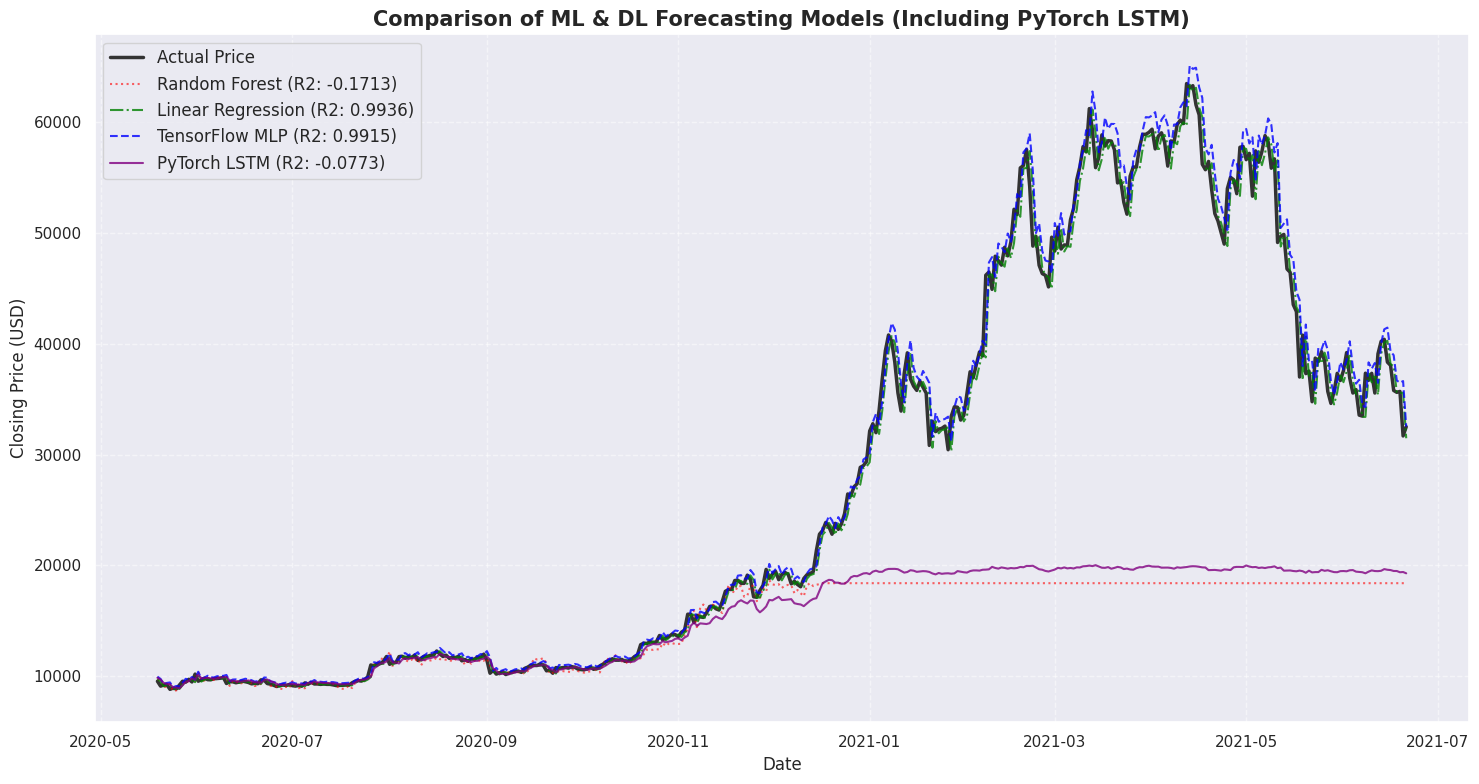

In [ ]:
# Comprehensive Model Comparison and Visualization
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 8))

# Plot ground truth and models
plt.plot(test_dates, y_test.values, label='Actual Price', color='#333333', linewidth=2.5)
plt.plot(test_dates, y_pred_test, label=f'Random Forest (R2: {r2:.4f})', color='red', linestyle=':', alpha=0.6)
plt.plot(test_dates, y_pred_lr, label=f'Linear Regression (R2: {r2_lr:.4f})', color='green', linestyle='-.', alpha=0.8)
plt.plot(test_dates, y_pred_nn, label=f'TensorFlow MLP (R2: {r2_nn:.4f})', color='blue', linestyle='--', alpha=0.8)
plt.plot(test_dates, y_pred_lstm, label=f'PyTorch LSTM (R2: {r2_lstm:.4f})', color='purple', linestyle='-', alpha=0.8)

plt.title('Comparison of ML & DL Forecasting Models (Including PyTorch LSTM)', fontsize=15, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Closing Price (USD)', fontsize=12)
plt.legend(fontsize=12, loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### 12. Saving to GitHub via Colab UI

To save this entire notebook to your GitHub account under **mohameniyaz**:

1. Go to the top menu and select **File** > **Save a copy in GitHub**.
2. Authorize Google Colab to access your GitHub account.
3. Choose your repository, branch, and specify a custom commit message (e.g., `Add Bitcoin ML & PyTorch LSTM forecasting models`).
4. Click **OK** to commit and publish the notebook.